# Krones — Copy-paste augmentation inspection

Generates a few synthetic samples per rare class and plots them so you can manually verify:
- placement (defect not on the rim, sits inside the bottle)
- blending (no hard rectangle visible)
- orientation/scale (still looks like the original defect)

**Run cell-by-cell.** If samples look bad, tweak the constants in the `# Knobs` cell and re-run from there. Once you're happy, run the full pipeline with `build_copypaste_aug.py`.

In [1]:
# Setup
import os
import json
import random
from collections import defaultdict
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFilter
import matplotlib.pyplot as plt
import matplotlib.patches as patches

ROOT = (
    "/home/dll0202/baksh/dataset/1st-krones-vision-ai-challenge"  # <-- adjust if needed
)
OUT = os.path.join(ROOT, "audit_output")
IMG_DIR = os.path.join(ROOT, "train_images")
CROPS_DIR = os.path.join(OUT, "crops")
ANN_PATH = os.path.join(ROOT, "train_annotations.json")

RARE_CLASSES = {
    "Insect": dict(
        placement="anywhere", max_tile_frac=0.05, rot=(0, 360), scale=(0.85, 1.20)
    ),
    "Foil / Semitransparent": dict(
        placement="anywhere", max_tile_frac=0.10, rot=(0, 360), scale=(0.85, 1.20)
    ),
    "Paint residue": dict(
        placement="anywhere", max_tile_frac=0.15, rot=(0, 360), scale=(0.85, 1.20)
    ),
    "Liquid": dict(
        placement="bottom_half", max_tile_frac=0.15, rot=(0, 360), scale=(0.85, 1.20)
    ),
}
DROPPED_CLASSES = ["Circlip", "Straw"]  # rely on geometric aug + sampler

N_SAMPLES_PER_CLASS = 4  # how many synth samples to generate per class for inspection
SEED = 42
rng = random.Random(SEED)

In [2]:
# Knobs - tune these and re-run cells below if samples look bad
MIN_DEFECT_AREA = 80  # px^2 minimum to keep a source defect
FEATHER_PX = 3  # gaussian blur radius on alpha mask edges
EDGE_MARGIN_FRAC = 0.10  # don't paste within this fraction of the ROI edge
MAX_PLACE_ATTEMPTS = 30
# (rotation/scale ranges and placement region are per-class in RARE_CLASSES above)

In [3]:
# Load metadata
ann = json.load(open(ANN_PATH))
cats = {c["id"]: c["name"] for c in ann["categories"]}
name2id = {v: k for k, v in cats.items()}
fname_of = {im["id"]: im["file_name"] for im in ann["images"]}

splits_df = pd.read_csv(os.path.join(OUT, "splits.csv"))
meta_df = pd.read_csv(os.path.join(OUT, "crops_meta.csv"))

train_image_ids = set(splits_df.loc[splits_df["split"] == "train", "image_id"])
good_train = splits_df[
    (splits_df["split"] == "train") & (splits_df["label"] == 0)
].merge(meta_df, on=["image_id", "file_name"], how="left")
print(f"good train crops as backgrounds: {len(good_train)}")

# bucket annotations by class (train split only, polygon segmentations only)
class_anns = defaultdict(list)
for a in ann["annotations"]:
    cname = cats[a["category_id"]]
    if cname not in RARE_CLASSES:
        continue
    if a["image_id"] not in train_image_ids:
        continue
    seg = a.get("segmentation")
    if not seg or isinstance(seg, dict):
        continue
    class_anns[cname].append((a["image_id"], seg, a["bbox"]))
for c in RARE_CLASSES.keys():
    print(f"{c:30s}: {len(class_anns[c])} candidate annotations")

good train crops as backgrounds: 11783
Insect                        : 25 candidate annotations
Foil / Semitransparent        : 34 candidate annotations
Paint residue                 : 176 candidate annotations
Liquid                        : 76 candidate annotations


In [4]:
# Augmentation helpers
def polygon_to_mask(seg_list, w, h, offset=(0, 0)):
    mask = Image.new("L", (w, h), 0)
    drawer = ImageDraw.Draw(mask)
    ox, oy = offset
    for poly in seg_list:
        xy = [(poly[i] - ox, poly[i + 1] - oy) for i in range(0, len(poly), 2)]
        drawer.polygon(xy, fill=255)
    return np.asarray(mask, dtype=np.uint8)


def extract_defect_tile(img, poly_list, bbox):
    x, y, w, h = [int(round(v)) for v in bbox]
    W, H = img.size
    x0, y0 = max(0, x), max(0, y)
    x1, y1 = min(W, x + w), min(H, y + h)
    if x1 <= x0 or y1 <= y0:
        return None
    crop = img.crop((x0, y0, x1, y1)).convert("L")
    mask = polygon_to_mask(poly_list, x1 - x0, y1 - y0, offset=(x0, y0))
    if FEATHER_PX > 0:
        mask = np.asarray(
            Image.fromarray(mask).filter(ImageFilter.GaussianBlur(FEATHER_PX)),
            dtype=np.uint8,
        )
    if mask.sum() < MIN_DEFECT_AREA * 255:
        return None
    rgba = Image.new("LA", (x1 - x0, y1 - y0))
    rgba.paste(crop, (0, 0))
    rgba.putalpha(Image.fromarray(mask))
    return rgba


def random_transform(tile, rng, rot_range, scale_range):
    angle = rng.uniform(*rot_range)
    scale = rng.uniform(*scale_range)
    nw = max(8, int(tile.width * scale))
    nh = max(8, int(tile.height * scale))
    return tile.resize((nw, nh), Image.LANCZOS).rotate(
        angle, resample=Image.BICUBIC, expand=True
    )


def find_paste_location(dW, dH, tw, th, roi, rng, placement="anywhere"):
    rx0, ry0, rx1, ry1 = roi
    rw, rh = rx1 - rx0, ry1 - ry0
    mx, my = int(rw * EDGE_MARGIN_FRAC), int(rh * EDGE_MARGIN_FRAC)
    rx0 += mx
    ry0 += my
    rx1 -= mx
    ry1 -= my
    if placement == "bottom_half":
        ry0 = ry0 + (ry1 - ry0) // 2
    vxmin, vxmax = rx0, rx1 - tw
    vymin, vymax = ry0, ry1 - th
    if vxmax <= vxmin or vymax <= vymin:
        return None
    return rng.randint(vxmin, vxmax), rng.randint(vymin, vymax)


def alpha_paste(dest_img, tile_la, pos):
    if dest_img.mode != "L":
        dest_img = dest_img.convert("L")
    tile_l = tile_la.convert("L")
    tile_a = tile_la.split()[-1]
    dest_img.paste(tile_l, pos, tile_a)
    return dest_img


def make_one_synth(cname, rng):
    """Returns dict with all the visual artifacts of one synth attempt, or None."""
    cfg = RARE_CLASSES[cname]
    anns = class_anns[cname]
    if not anns:
        return None
    src_iid, seg, sbbox = anns[rng.randrange(len(anns))]
    src_path = os.path.join(IMG_DIR, fname_of[src_iid])
    if not os.path.exists(src_path):
        return None
    with Image.open(src_path) as src_img:
        src_full = src_img.copy()
        tile = extract_defect_tile(src_img, seg, sbbox)
    if tile is None:
        return None
    tile_t = random_transform(tile, rng, cfg["rot"], cfg["scale"])
    d = good_train.sample(1, random_state=rng.randint(0, 1 << 30)).iloc[0]
    dest_path = os.path.join(CROPS_DIR, d["file_name"])
    if not os.path.exists(dest_path):
        return None
    with Image.open(dest_path) as dest_img:
        dest_orig = dest_img.copy()
        dW, dH = dest_img.size
        roi_x0 = max(0, d["roi_x"] - d["crop_x0"])
        roi_y0 = max(0, d["roi_y"] - d["crop_y0"])
        roi_x1 = min(dW, roi_x0 + d["roi_w"])
        roi_y1 = min(dH, roi_y0 + d["roi_h"])
        roi_in_crop = (int(roi_x0), int(roi_y0), int(roi_x1), int(roi_y1))
        # size filter
        roi_area = max(1, (roi_x1 - roi_x0) * (roi_y1 - roi_y0))
        if tile_t.width * tile_t.height > cfg["max_tile_frac"] * roi_area:
            return None  # tile too big - rejected
        pos = None
        for _ in range(MAX_PLACE_ATTEMPTS):
            pos = find_paste_location(
                dW,
                dH,
                tile_t.width,
                tile_t.height,
                roi_in_crop,
                rng,
                placement=cfg["placement"],
            )
            if pos:
                break
        if pos is None:
            return None
        out = alpha_paste(dest_img.copy(), tile_t, pos)
    return dict(
        class_name=cname,
        src_iid=src_iid,
        src_full=src_full,
        src_bbox=sbbox,
        tile=tile,
        tile_t=tile_t,
        dest_orig=dest_orig,
        dest_file=d["file_name"],
        roi_in_crop=roi_in_crop,
        pos=pos,
        out=out,
    )

In [5]:
# Generate samples
all_samples = {}
for cname in RARE_CLASSES.keys():
    samples = []
    attempts = 0
    while len(samples) < N_SAMPLES_PER_CLASS and attempts < N_SAMPLES_PER_CLASS * 15:
        s = make_one_synth(cname, rng)
        attempts += 1
        if s is not None:
            samples.append(s)
    all_samples[cname] = samples
    print(f"{cname:30s}: produced {len(samples)} sample(s) in {attempts} attempts")

Insect                        : produced 4 sample(s) in 4 attempts
Foil / Semitransparent        : produced 4 sample(s) in 4 attempts
Paint residue                 : produced 4 sample(s) in 8 attempts
Liquid                        : produced 4 sample(s) in 9 attempts


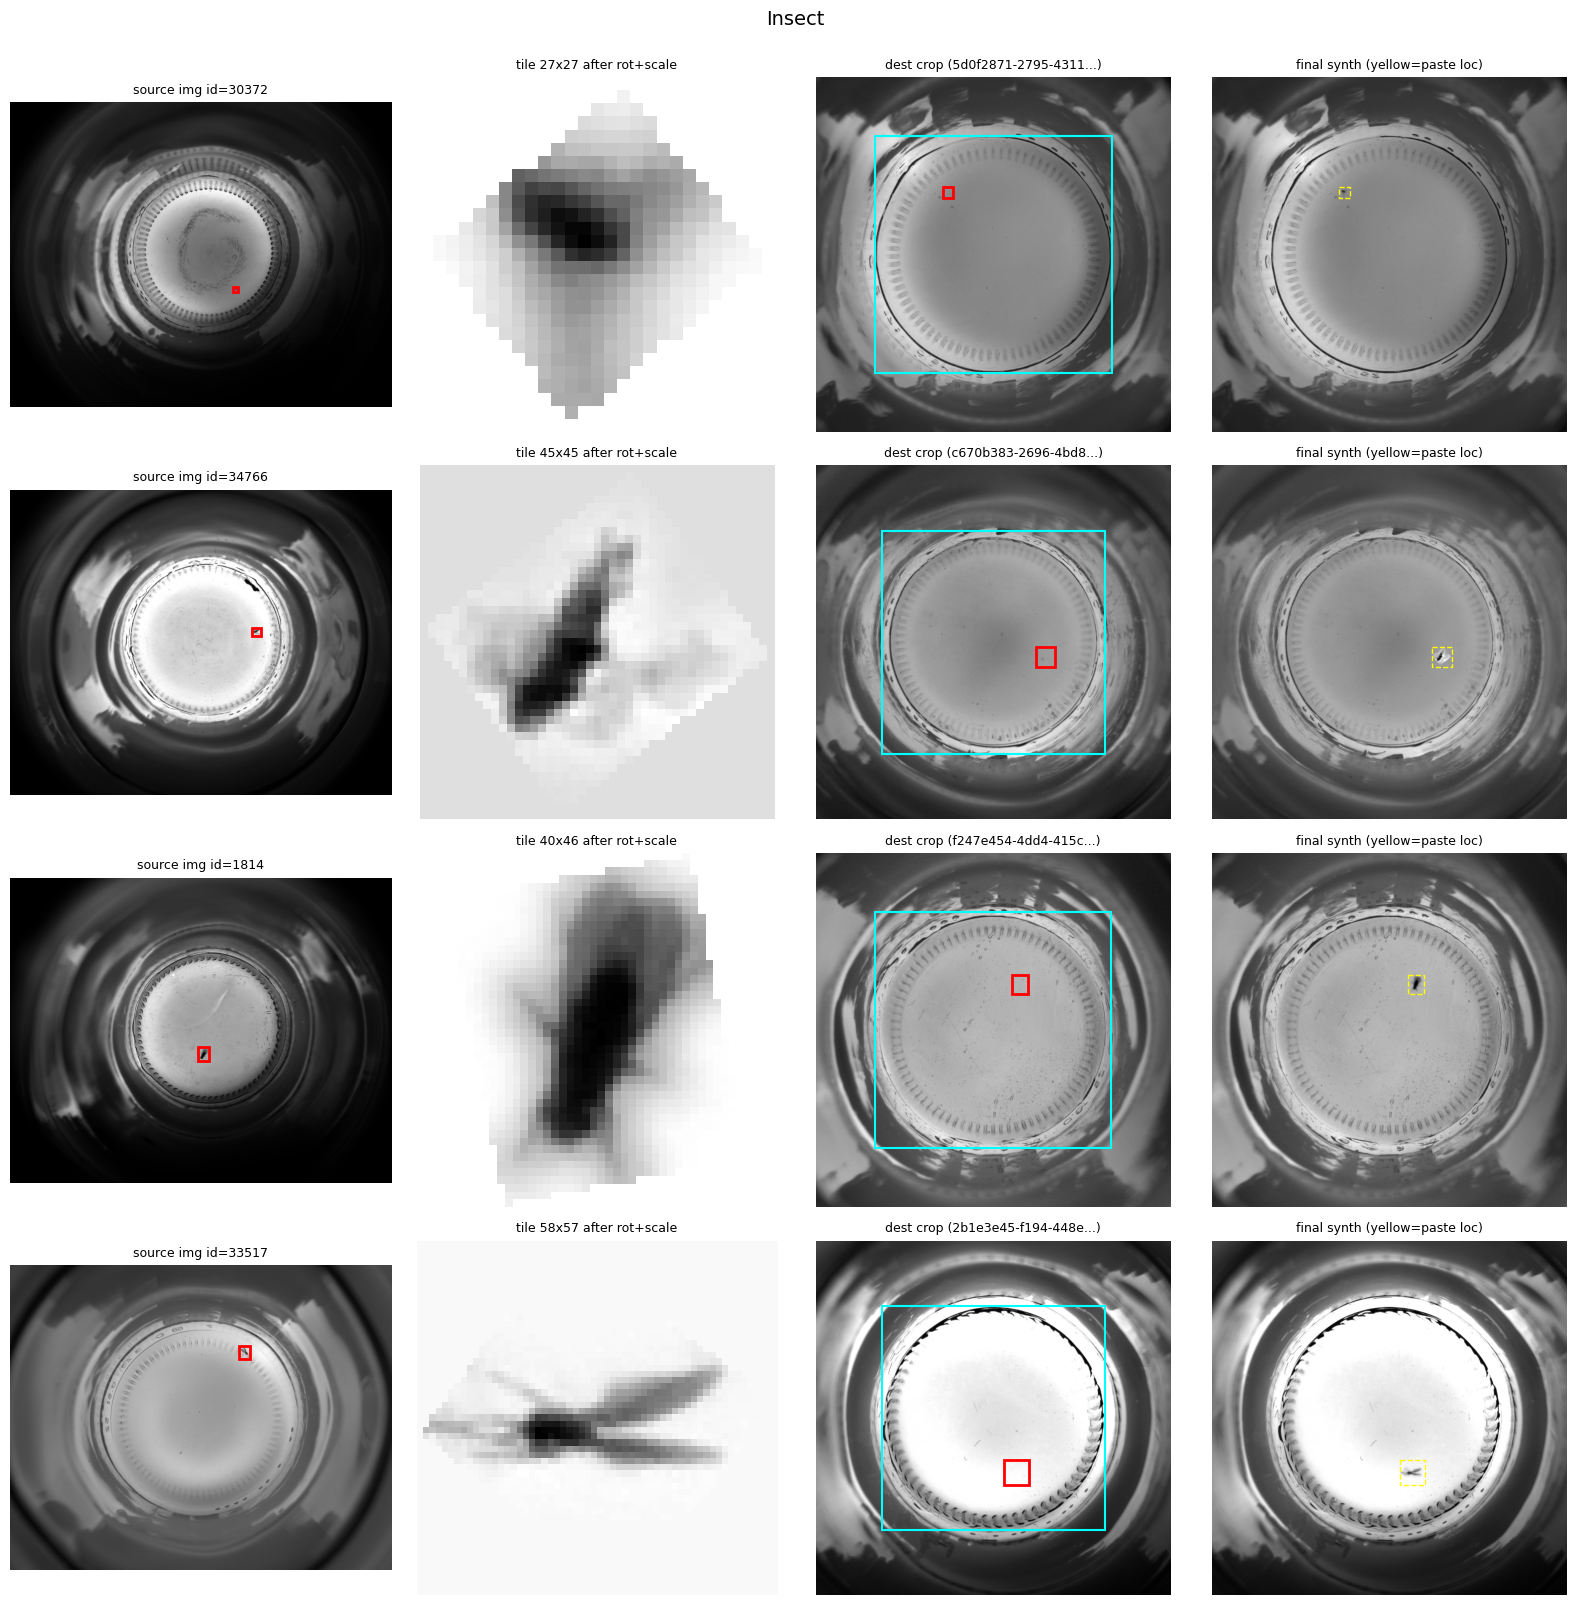

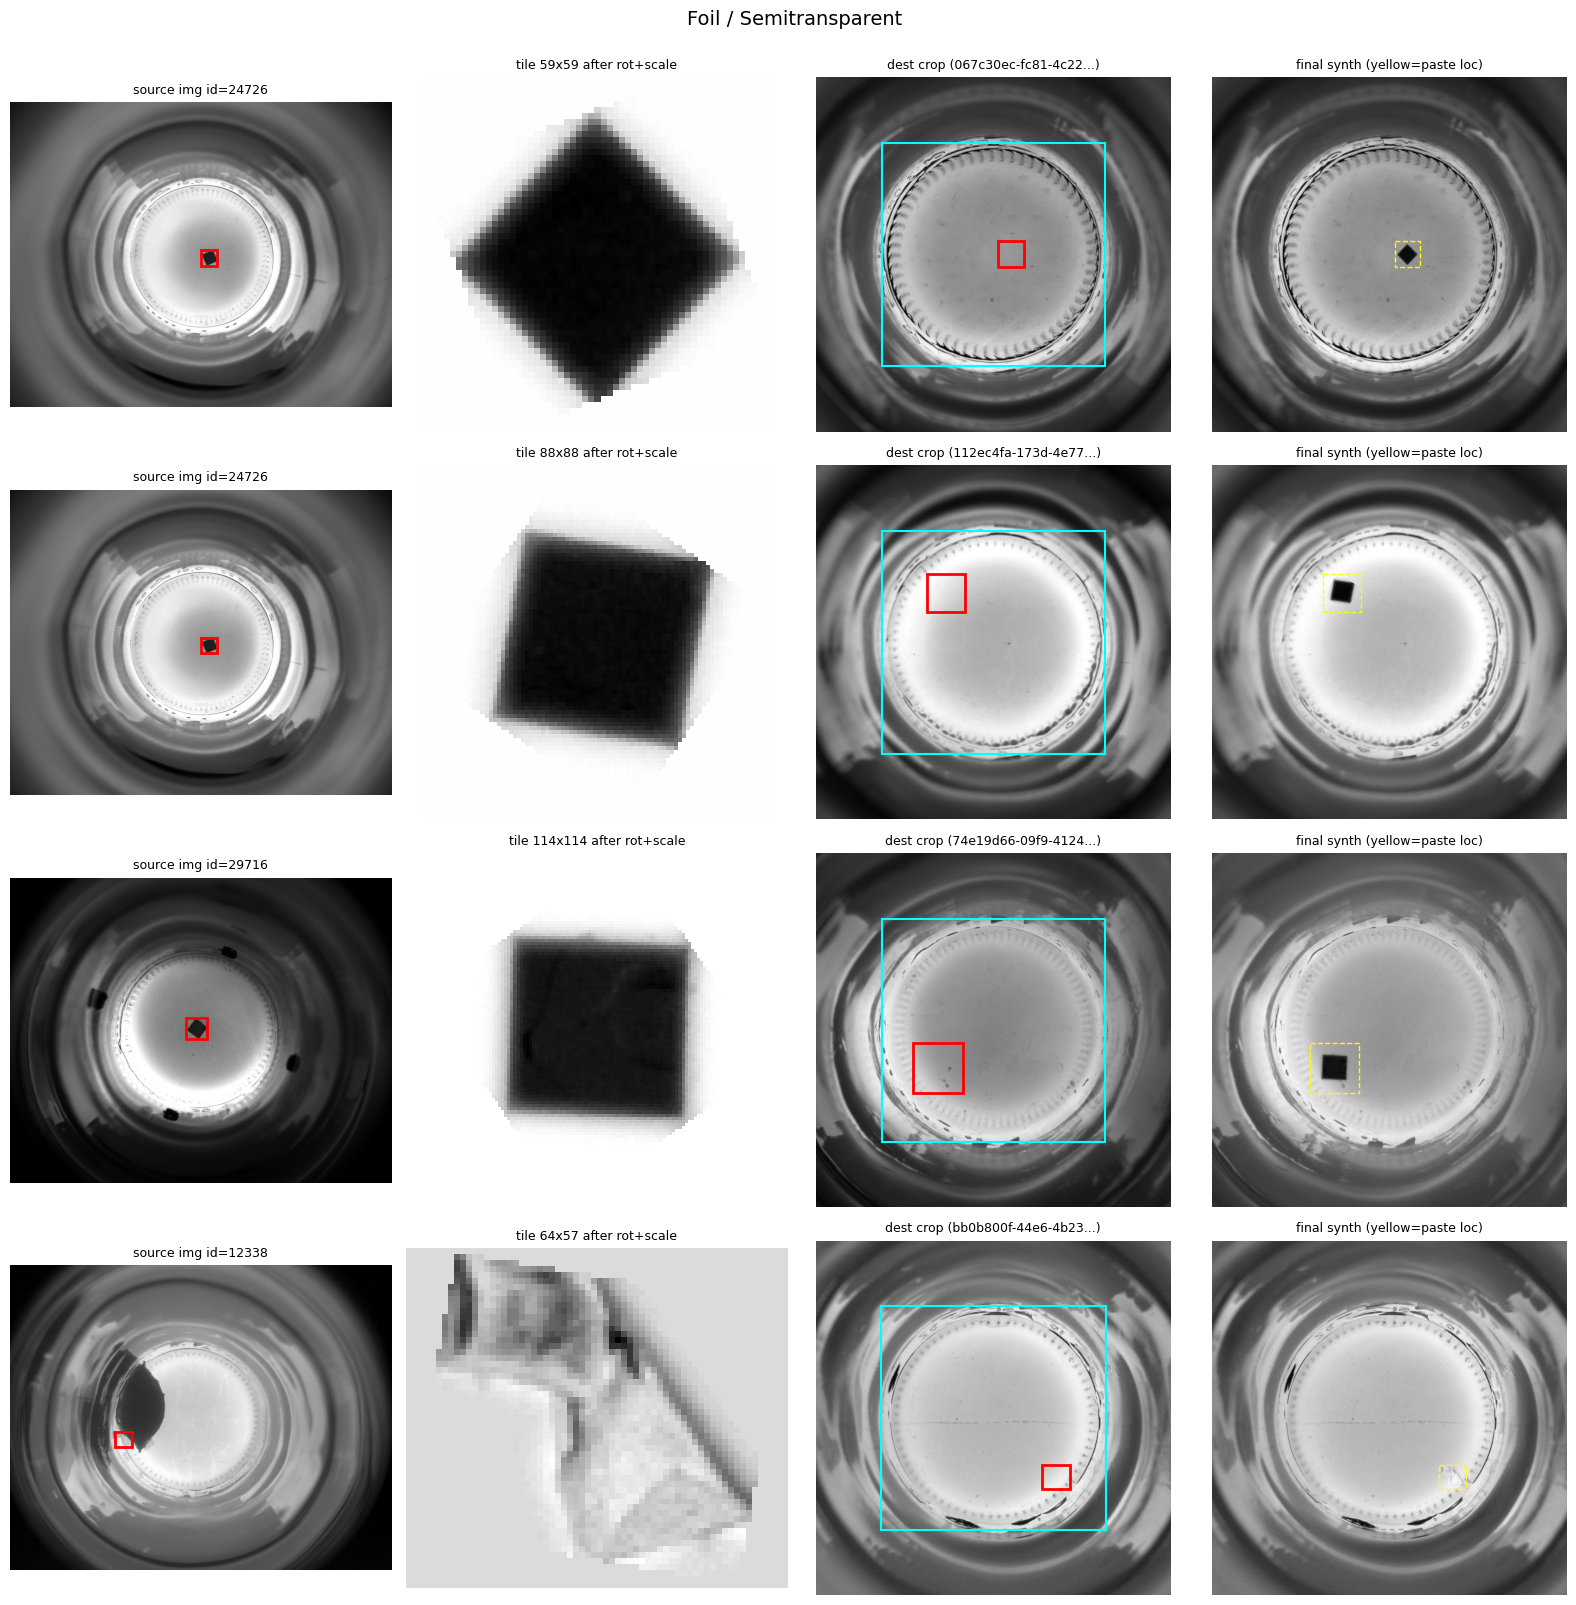

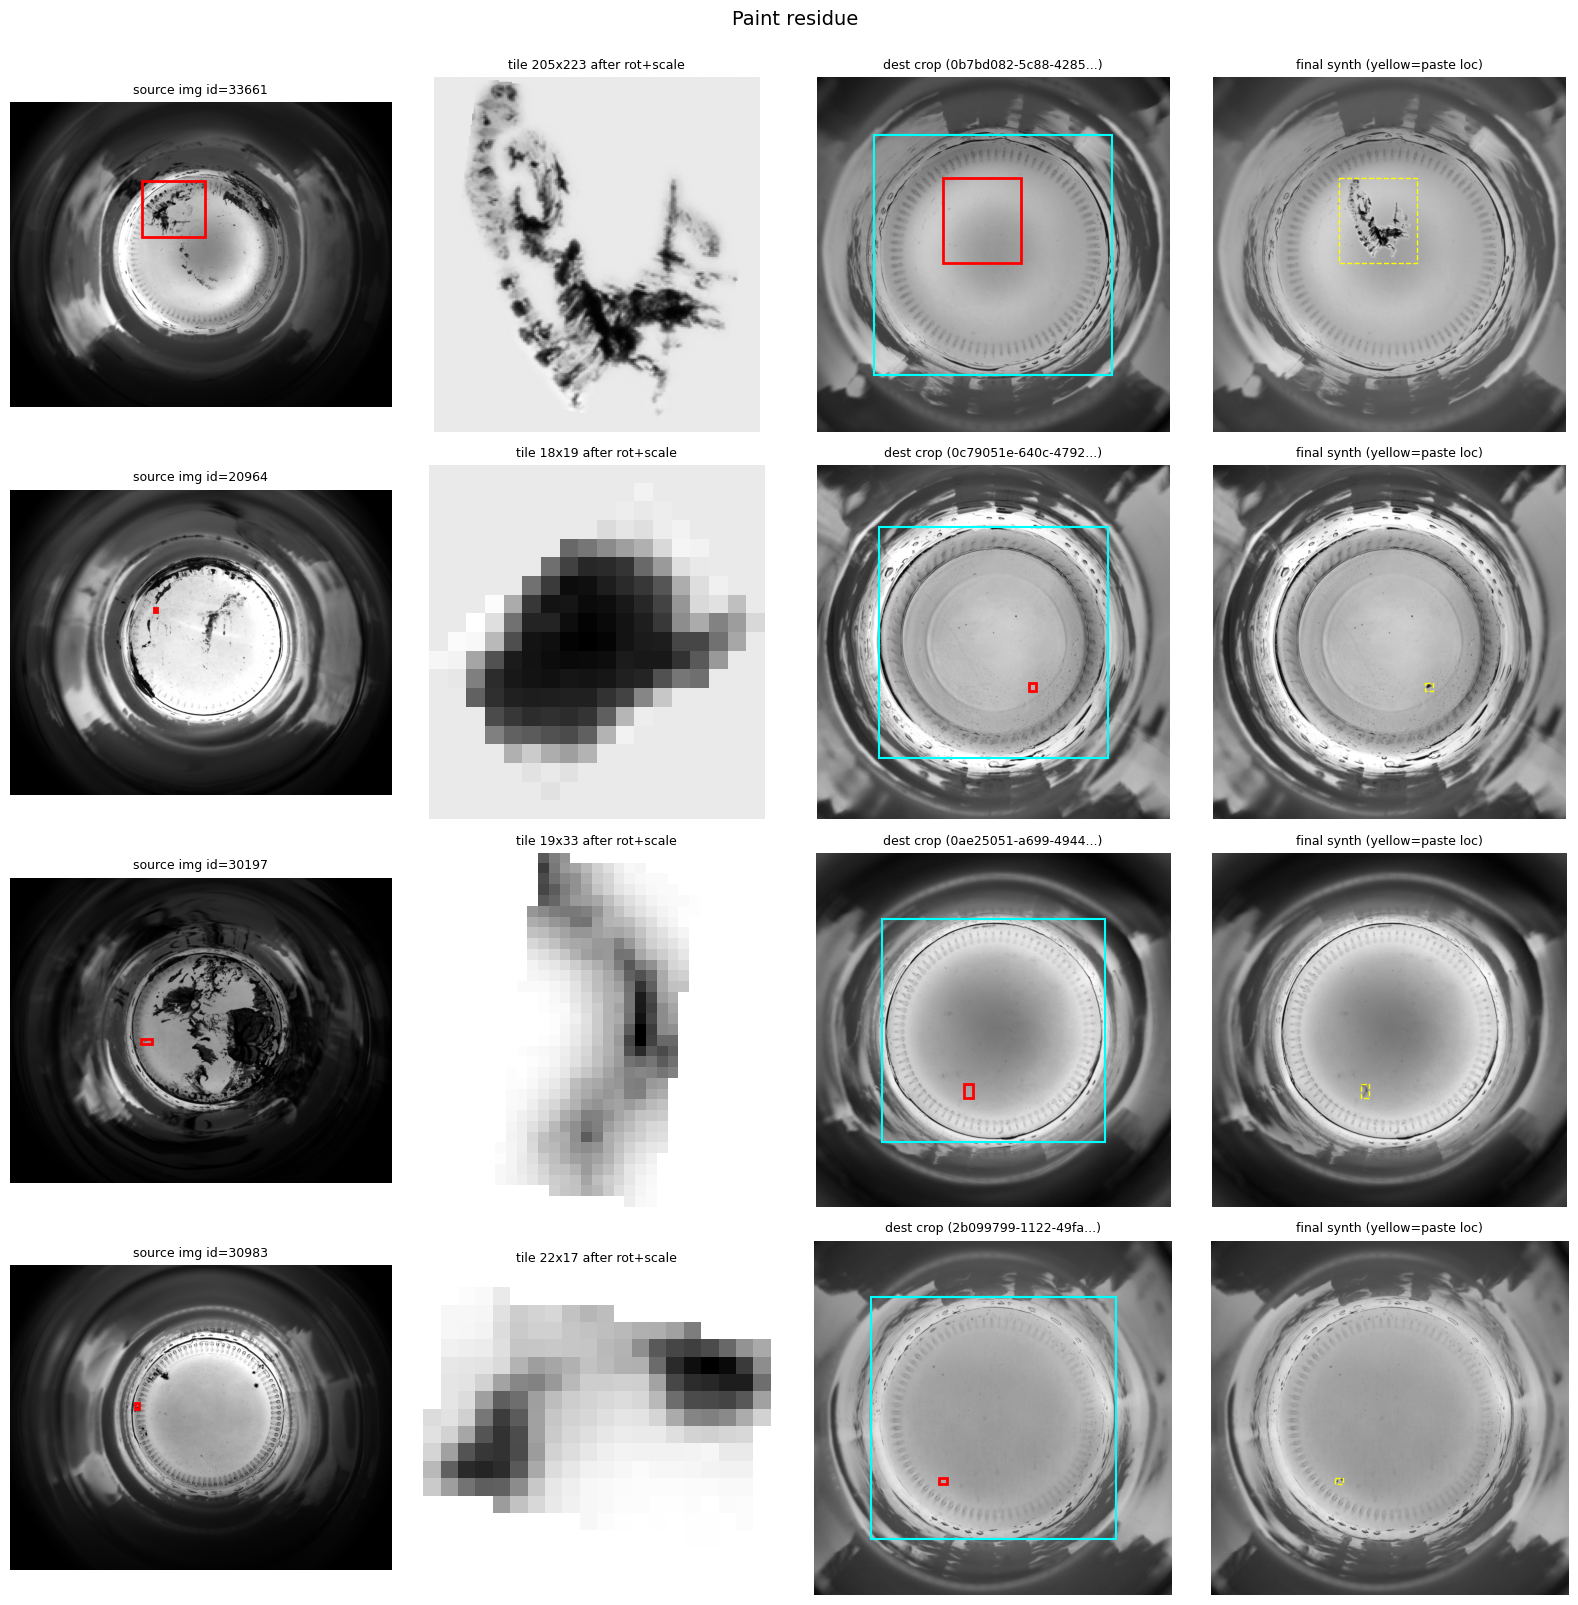

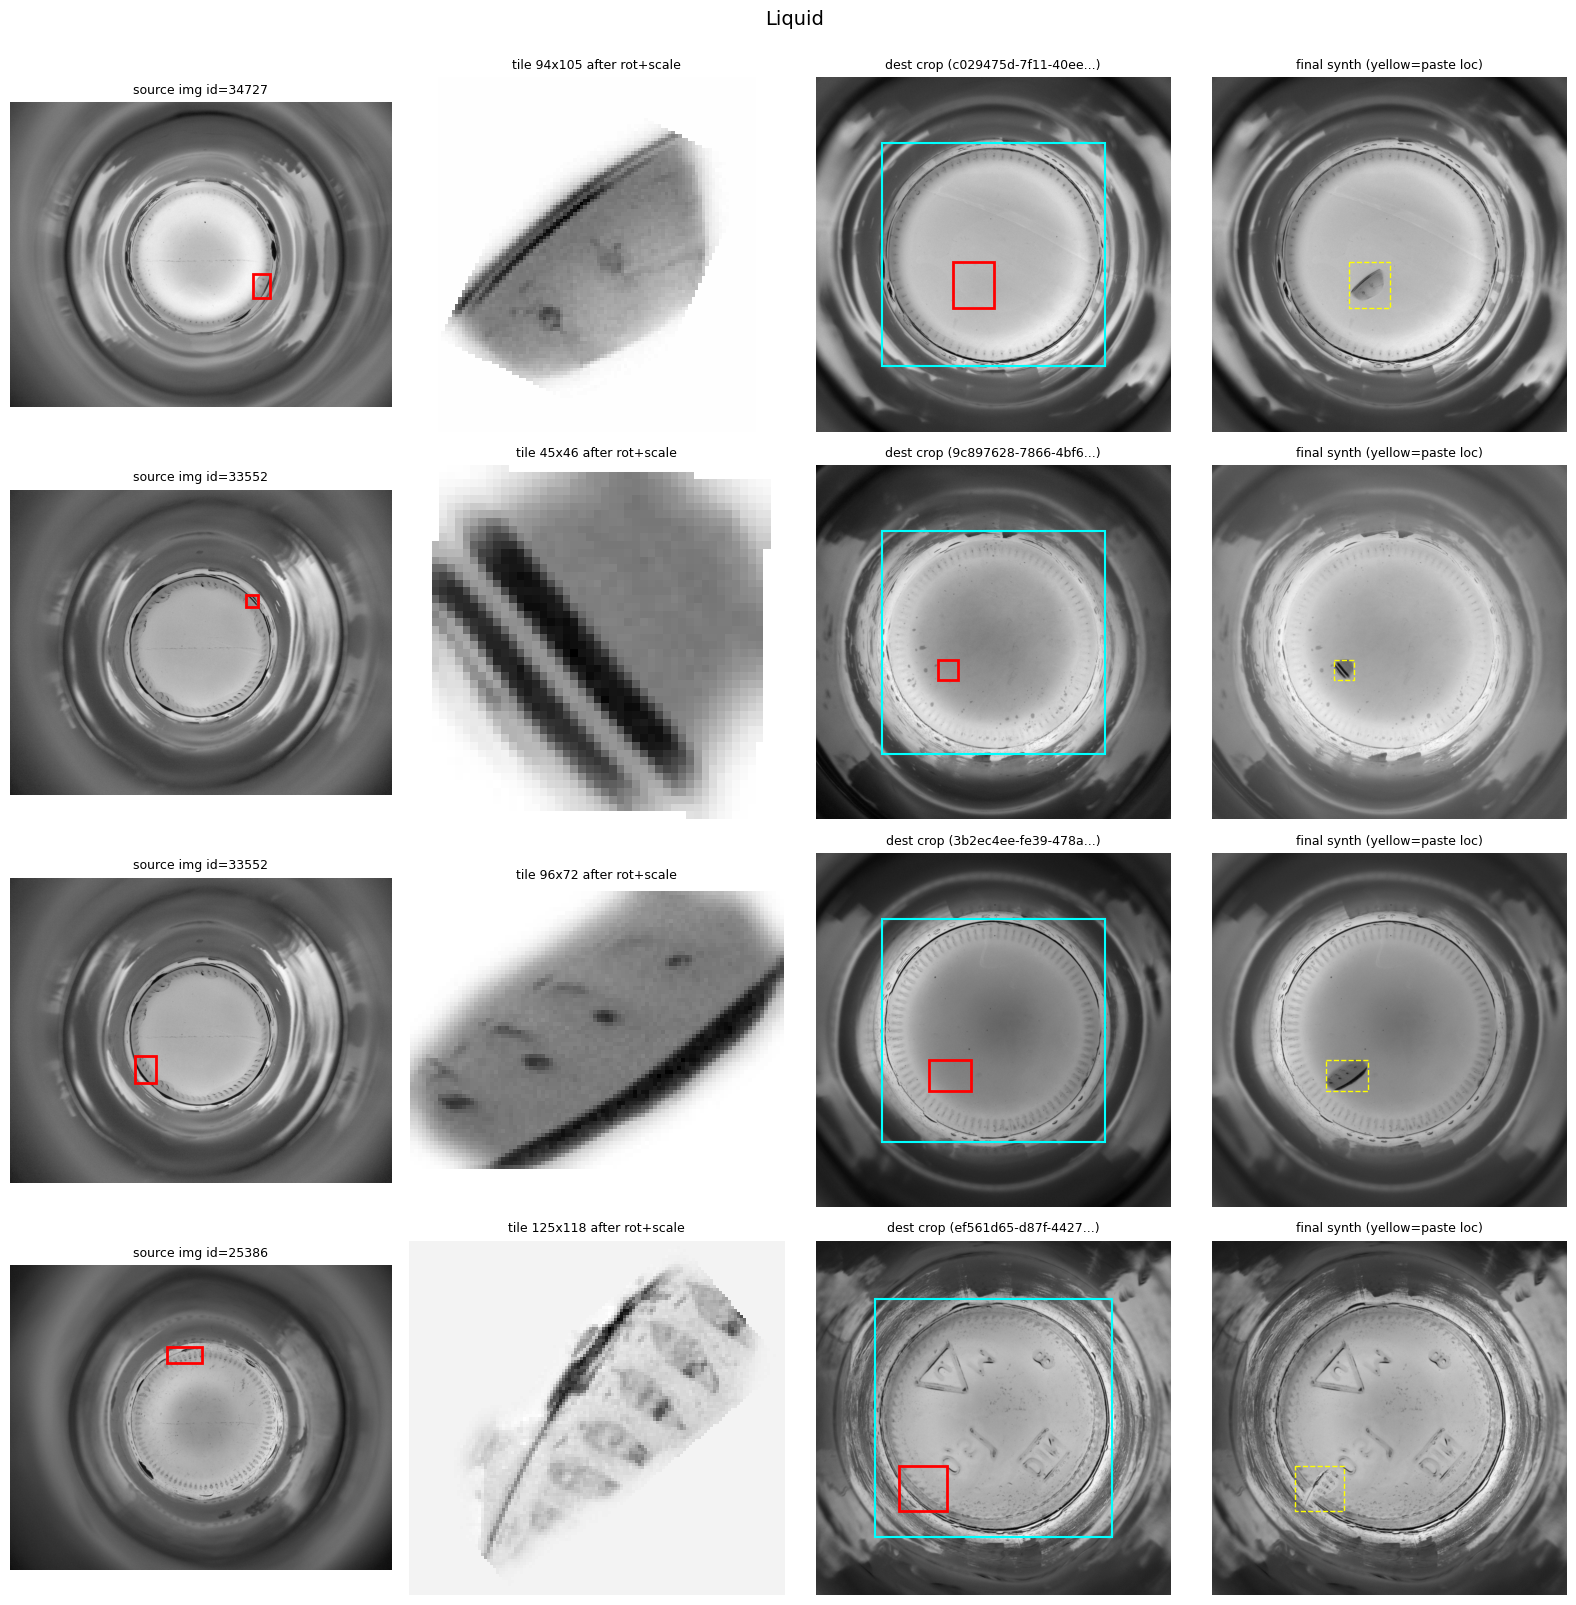

In [6]:
# Visualize: one row per sample, 4 columns:
#   [source full image w/ bbox] [extracted tile] [destination crop w/ ROI box + paste box] [final synth]
def plot_samples(samples, class_name):
    if not samples:
        print(f"{class_name}: no samples to plot")
        return
    n = len(samples)
    fig, axes = plt.subplots(n, 4, figsize=(16, 4 * n))
    if n == 1:
        axes = axes.reshape(1, -1)
    fig.suptitle(class_name, fontsize=14, y=1.0)
    for i, s in enumerate(samples):
        # column 0 - source full image with bbox
        axes[i, 0].imshow(s["src_full"], cmap="gray")
        x, y, w, h = s["src_bbox"]
        axes[i, 0].add_patch(
            patches.Rectangle((x, y), w, h, fill=False, ec="red", lw=2)
        )
        axes[i, 0].set_title(f"source img id={s['src_iid']}", fontsize=9)
        axes[i, 0].axis("off")
        # column 1 - extracted (transformed) tile
        tile_rgba = s["tile_t"]
        # show with checkerboard so transparency is visible
        bg = Image.new("L", tile_rgba.size, 200)
        bg.paste(tile_rgba.convert("L"), (0, 0), tile_rgba.split()[-1])
        axes[i, 1].imshow(bg, cmap="gray")
        axes[i, 1].set_title(
            f"tile {tile_rgba.size[0]}x{tile_rgba.size[1]} after rot+scale", fontsize=9
        )
        axes[i, 1].axis("off")
        # column 2 - destination with ROI box + paste box
        axes[i, 2].imshow(s["dest_orig"], cmap="gray")
        rx0, ry0, rx1, ry1 = s["roi_in_crop"]
        axes[i, 2].add_patch(
            patches.Rectangle(
                (rx0, ry0),
                rx1 - rx0,
                ry1 - ry0,
                fill=False,
                ec="cyan",
                lw=1.5,
                label="ROI",
            )
        )
        px, py = s["pos"]
        tw, th = s["tile_t"].size
        axes[i, 2].add_patch(
            patches.Rectangle(
                (px, py), tw, th, fill=False, ec="red", lw=2, label="paste"
            )
        )
        axes[i, 2].set_title(f"dest crop ({s['dest_file'][:18]}...)", fontsize=9)
        axes[i, 2].axis("off")
        # column 3 - final synth
        axes[i, 3].imshow(s["out"], cmap="gray")
        axes[i, 3].add_patch(
            patches.Rectangle((px, py), tw, th, fill=False, ec="yellow", lw=1, ls="--")
        )
        axes[i, 3].set_title("final synth (yellow=paste loc)", fontsize=9)
        axes[i, 3].axis("off")
    plt.tight_layout()
    plt.show()


for cname in RARE_CLASSES.keys():
    plot_samples(all_samples[cname], cname)

## Zoom view — only the paste region

Useful for checking blending quality (hard seam, halo). Shows just the patch around the pasted defect at high resolution.

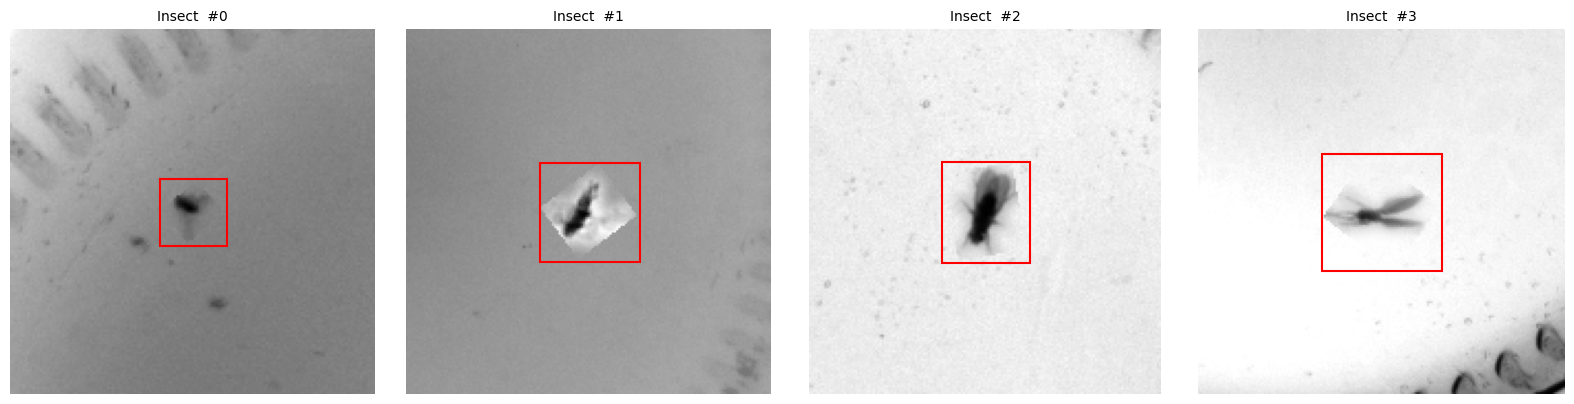

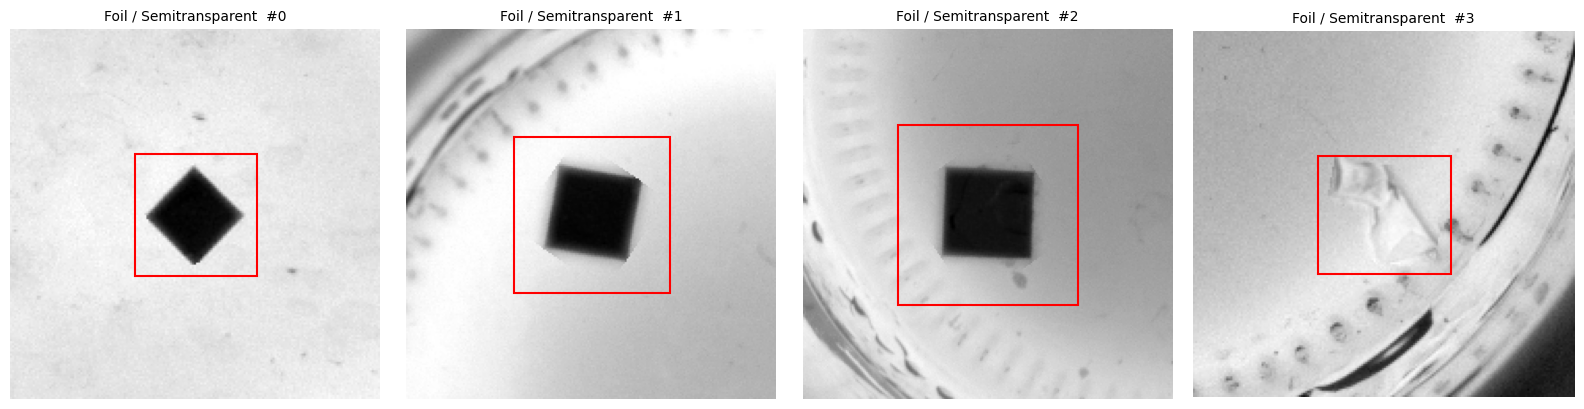

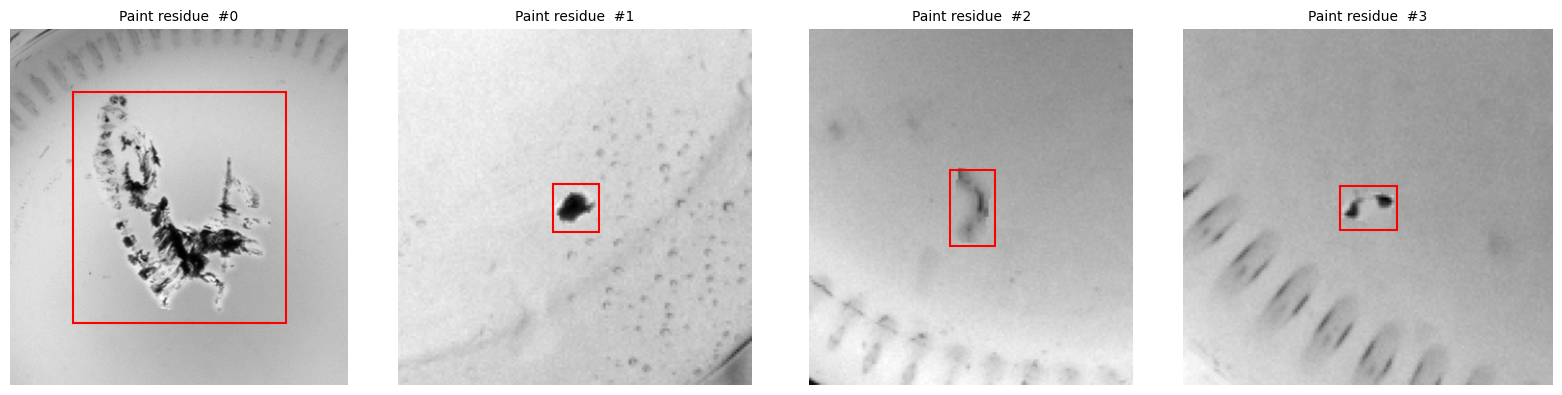

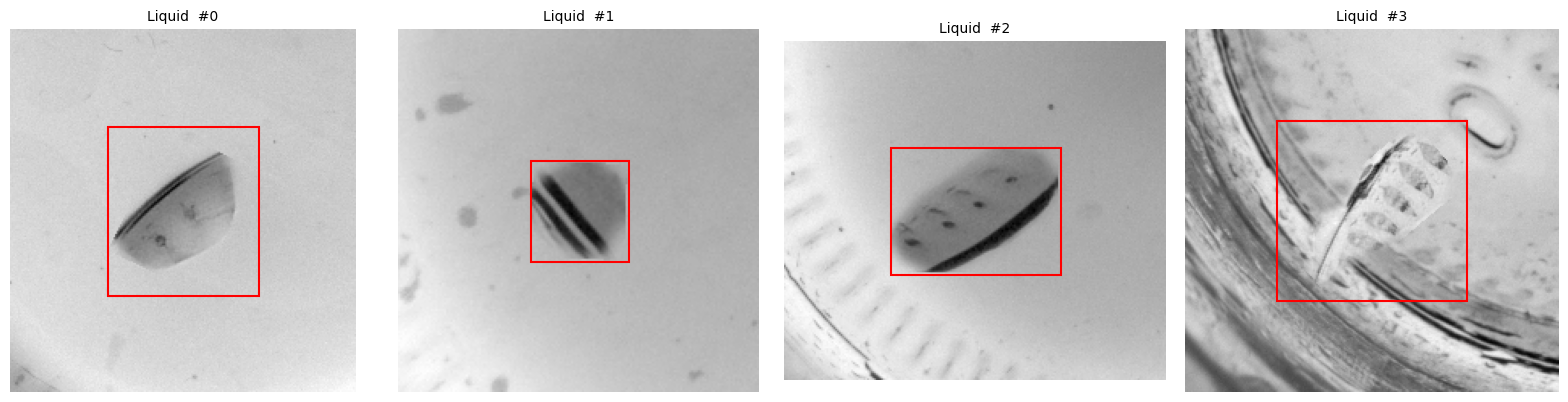

In [7]:
ZOOM_PAD = 60
for cname in RARE_CLASSES.keys():
    samples = all_samples[cname]
    if not samples:
        continue
    n = len(samples)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    if n == 1:
        axes = [axes]
    for i, s in enumerate(samples):
        px, py = s["pos"]
        tw, th = s["tile_t"].size
        x0 = max(0, px - ZOOM_PAD)
        y0 = max(0, py - ZOOM_PAD)
        x1 = min(s["out"].width, px + tw + ZOOM_PAD)
        y1 = min(s["out"].height, py + th + ZOOM_PAD)
        zoom = s["out"].crop((x0, y0, x1, y1))
        axes[i].imshow(zoom, cmap="gray")
        axes[i].add_patch(
            patches.Rectangle((px - x0, py - y0), tw, th, fill=False, ec="red", lw=1.5)
        )
        axes[i].set_title(f"{cname}  #{i}", fontsize=10)
        axes[i].axis("off")
    plt.tight_layout()
    plt.show()

## Decision checklist

For each class, ask:
1. **Placement** — Is the paste inside the bottle interior, not on the rim?
2. **Blending** — Is there a visible rectangle around the paste? Halo? If yes, increase `FEATHER_PX`.
3. **Realism** — Does the rotated/scaled defect still resemble the originals, or did rotation make it look alien?
4. **Size** — Are pastes too tiny to matter, or so big they fill the bottle?

If anything looks wrong, edit the **Knobs** cell, re-run from `make_one_synth` onward, and regenerate. Once you're satisfied, run `build_copypaste_aug.py` for the full ~1000 images.